# Resilience of the U.S. Passenger Air Network (2025)
## Author: Jaime Alfonso Martínez Vogel
**Final project for the Data Visualization course**

---

### 1. Context

Flying from one city to another is rarely a direct trip, because of the connection system behind the air network.

The air system can be seen as a **graph**: a minority of airports (the biggest and best known) concentrate a large number of connections, while the rest only have a few.

That makes the system **efficient**, but also **fragile**. If a critical airport fails (extreme weather, operational failure, closure), the effect spreads to hundreds of routes, even though everything is connected to everything else.

The analytical question guiding this project is:
> **Decision question:** Which airports are so critical that their failure would fragment the U.S. air network in 2025?

**Why it matters:** identifying them helps prioritize investment in **redundancy and resilience**. This is useful for an airline, an insurer, or infrastructure planning.

### 2. Data source

The geographic scope of this project is the `U.S.`, because the data was easier to access. The **data sources** used:

| Item | Detail |
|---|---|
| **Route data** | Bureau of Transportation Statistics (BTS) T-100 Domestic Segment (U.S. carriers), year **2025**. Public domain (U.S. government). |
| **Coordinates** | OpenFlights (`jpatokal/openflights`), joined by IATA code |

**Scope and limitations:**
- Covers **U.S. airlines ONLY** (domestic network). It is not a global network.
- **Class F** = scheduled passenger service. Other classes (cargo, non-scheduled flights) were dropped to keep a clean commercial network.
- The resilience analysis runs on the **main connected component**: 697 of 718 airports (the other 21 sit in small disconnected clusters).

### 3. Setup

> Run this notebook from the `notebooks/` folder. Put the T-100 CSV (`T_T100D_SEGMENT_ALL_CARRIER.csv`, year 2025) in `data/` (see `data/README.md`). Airport coordinates are downloaded automatically from GitHub.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import plotly.express as px
import plotly.graph_objects as go

pd.options.display.float_format = lambda x: f"{x:,.2f}"

# Consistent visual template for the whole project
TEMPLATE = "plotly_white"
BLUE, RED, GRAY, AMBER = "#2563eb", "#dc2626", "#97a0ab", "#f59e0b"

# Real geographic projection (framed on the U.S. region)
GEO = dict(
    projection_type="natural earth",
    lonaxis=dict(range=[-180, -64]),
    lataxis=dict(range=[15, 72]),
    showland=True, landcolor="#f8fafc",
    showcountries=True, countrycolor="#cbd5e1",
    showcoastlines=True, coastlinecolor="#cbd5e1",
    showsubunits=True, subunitcolor="#e2e8f0",
    bgcolor="white",  # ocean
)

# Files and folders
DATA_DIR = Path("../data")
DOCS_DIR = Path("../docs")
T100_FILE = DATA_DIR / "T_T100D_SEGMENT_ALL_CARRIER.csv"
AIRPORTS_URL = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/airports.dat"
AIRPORTS_FILE = DATA_DIR / "airports.dat"  # optional local fallback if the URL is unreachable

# Save every figure as a standalone interactive HTML page in docs/ (used by the README / GitHub Pages)
EXPORT_HTML = True

def show(fig, name):
    """Display a figure and, if EXPORT_HTML is on, save an interactive copy to docs/."""
    fig.show()
    if EXPORT_HTML:
        DOCS_DIR.mkdir(exist_ok=True)
        fig.write_html(DOCS_DIR / f"{name}.html", include_plotlyjs="cdn")

print("Libraries loaded ✔")

Libraries loaded ✔


### 4. Loading and cleaning → edge list

We go from raw rows (one per airline × aircraft × month × segment) to a **list of unique routes** (the edges of the graph) with their yearly passengers.

In [3]:
# 4.1 Load 2025
raw = pd.read_csv(T100_FILE)
print("Raw rows:", f"{len(raw):,}", "| Columns:", raw.shape[1])

# 4.2 Keep REGULAR passenger flights that DID operate
mask = (raw["CLASS"] == "F") & (raw["DEPARTURES_PERFORMED"] > 0) & (raw["PASSENGERS"] > 0)
df = raw[mask].copy()

# 4.3 Remove self-loops (origin == destination)
df = df[df["ORIGIN"] != df["DEST"]]

print("Rows after cleaning:", f"{len(df):,}")

# 4.4 Aggregate to ORIGIN -> DEST routes (airport codes)
directed_edges = (df
                  .groupby(["ORIGIN", "DEST"], as_index=False)
                  .agg(passengers=("PASSENGERS", "sum"),
                       flights=("DEPARTURES_PERFORMED", "sum")))

print("\nUnique directed routes:", f"{len(directed_edges):,}")
display(directed_edges.head(3))

# 4.5 Collapse to undirected (A-B and B-A are the same connection)
directed_edges["a"] = directed_edges[["ORIGIN", "DEST"]].min(axis=1)  # alphabetical minimum per row
directed_edges["b"] = directed_edges[["ORIGIN", "DEST"]].max(axis=1)  # alphabetical maximum per row

# 4.6 Main (undirected) route table
edges = (directed_edges
         .groupby(["a", "b"], as_index=False)
         .agg(passengers=("passengers", "sum"),
              flights=("flights", "sum")))

print("Undirected routes:", f"{len(edges):,}")
edges.sort_values("passengers", ascending=False).head()

Raw rows: 458,361 | Columns: 22
Rows after cleaning: 342,524

Unique directed routes: 13,715


,ORIGIN,DEST,passengers,flights
0,06A,A43,1.00,1.00
1,1G4,BLD,704.00,97.00
2,6AK,BET,4.00,2.00


Undirected routes: 8,409


,a,b,passengers,flights
5979,JFK,LAX,"2,912,378.00","20,298.00"
6564,LGA,ORD,"2,769,545.00","22,407.00"
6459,LAX,SFO,"2,708,280.00","23,757.00"
856,ATL,MCO,"2,697,498.00","16,158.00"
6301,LAS,LAX,"2,429,964.00","20,437.00"


In [4]:
# 4.7 Build the graph and keep the main connected component
G_full = nx.from_pandas_edgelist(edges, "a", "b", edge_attr=["passengers", "flights"])

print("Full graph:", G_full.number_of_nodes(), "nodes,",
      nx.number_connected_components(G_full), "components")

main_component = max(nx.connected_components(G_full), key=len)
G = G_full.subgraph(main_component).copy()  # keep the component with the most nodes

print("Main component (analyzed network):",
      G.number_of_nodes(), "airports,", G.number_of_edges(), "routes")

Full graph: 718 nodes, 5 components
Main component (analyzed network): 697 airports, 8375 routes


### 5. Centrality metrics + coordinates

We compute three measures per airport:
- **Degree:** how many distinct airports it connects to (how much of a *hub* it is).
- **Passengers:** total volume (how *big* it is).
- **Betweenness:** in how many shortest paths between other pairs it acts as a *bridge*. An airport can be a critical bridge without being big.

In [5]:
# 5.1 Metrics
degree = dict(G.degree())  # {airport: number of connections}
node_passengers = {n: sum(d["passengers"] for _, _, d in G.edges(n, data=True)) for n in G.nodes()}  # total passengers per airport
betweenness = nx.betweenness_centrality(G, normalized=True)  # {airport: centrality}

# 5.2 Coordinates from OpenFlights (by IATA code)
cols = ["id", "name", "city", "country", "IATA", "ICAO", "lat", "lon", "alt", "tz", "dst", "tzdb", "type", "src"]
try:
    ap = pd.read_csv(AIRPORTS_URL, header=None, names=cols, na_values=["\\N"])
except Exception:
    ap = pd.read_csv(AIRPORTS_FILE, header=None, names=cols, na_values=["\\N"])

ap = (ap
      .dropna(subset=["IATA"])
      .drop_duplicates("IATA")
      .set_index("IATA"))

# 5.3 Master table of nodes
nodes = pd.DataFrame({"IATA": list(G.nodes())})
nodes["degree"] = nodes["IATA"].map(degree)
nodes["passengers"] = nodes["IATA"].map(node_passengers)
nodes["betweenness"] = nodes["IATA"].map(betweenness)

# 5.4 Final table: left join to attach airport name, city and coordinates
nodes = nodes.join(ap[["name", "city", "lat", "lon"]], on="IATA")
print("Airports with coordinates:", nodes["lat"].notna().sum(), "of", len(nodes))
nodes.sort_values("passengers", ascending=False).head()

Airports with coordinates: 603 of 697


,IATA,degree,passengers,betweenness,name,city,lat,lon
9,ATL,179,"88,602,612.00",0.04,Hartsfield Jackson Atlanta International Airport,Atlanta,33.64,-84.43
23,DEN,215,"75,407,354.00",0.12,Denver International Airport,Denver,39.86,-104.67
24,DFW,211,"70,345,915.00",0.06,Dallas Fort Worth International Airport,Dallas-Fort Worth,32.90,-97.04
46,ORD,221,"67,236,356.00",0.11,Chicago O'Hare International Airport,Chicago,41.98,-87.90
36,LAX,154,"49,696,577.00",0.02,Los Angeles International Airport,Los Angeles,33.94,-118.41


## Exploratory Data Analysis

### In an air network it may seem that everything is connected equally, but in reality it is not

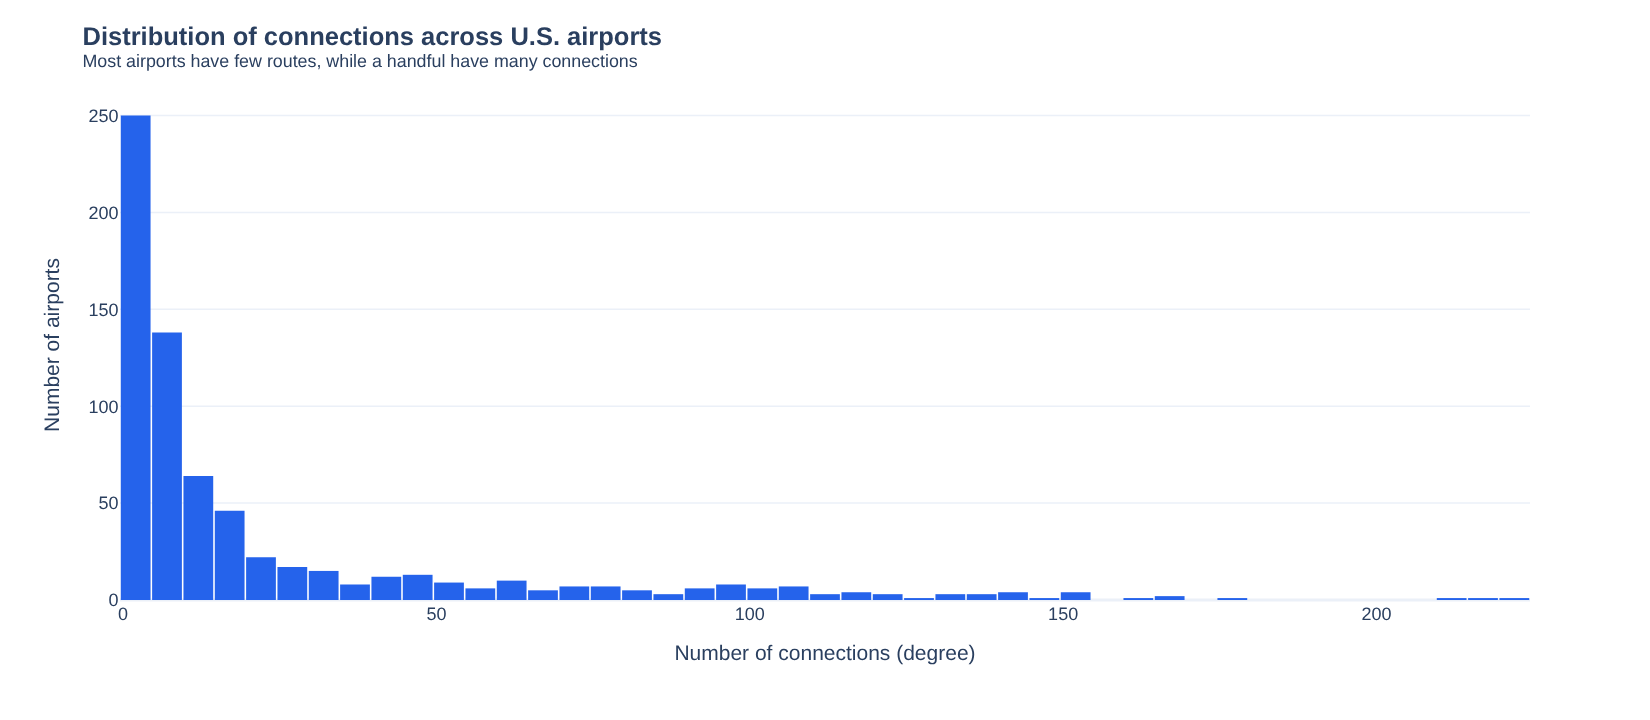

In [6]:
# Degree distribution: how are connections shared out?
fig = px.histogram(nodes,
                   x="degree",
                   nbins=50,
                   template=TEMPLATE,
                   color_discrete_sequence=[BLUE])

fig.update_layout(
    title="<b>Distribution of connections across U.S. airports</b><br><sup>Most airports have few routes, while a handful have many connections</sup>",
    xaxis_title="Number of connections (degree)",
    yaxis_title="Number of airports",
    bargap=0.05,
    height=480)

show(fig, "01_degree_distribution")

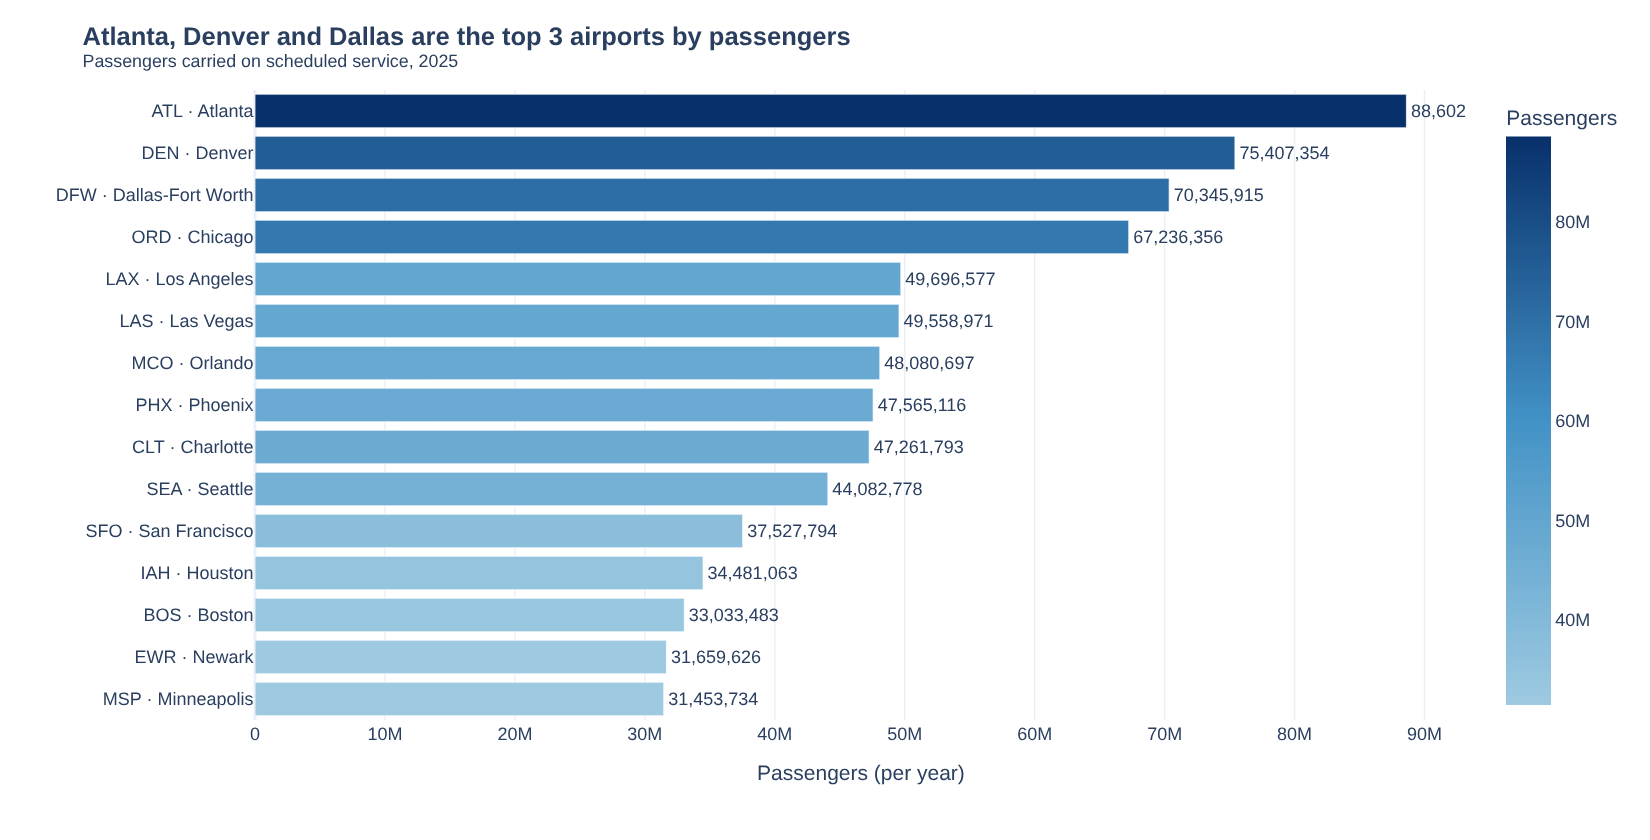

In [7]:
# Top 15 airports by passengers
top = nodes.sort_values("passengers", ascending=False).head(15).iloc[::-1]
top["label"] = top["IATA"] + " · " + top["city"].fillna("")

fig = px.bar(top,
             x="passengers",
             y="label",
             orientation="h",
             template=TEMPLATE,
             hover_data={"passengers": ":,.0f"},
             color="passengers",
             color_continuous_scale=[[0, "#9ecae1"], [0.5, "#4292c6"], [1, "#08306b"]], text="passengers")

fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside")
fig.update_layout(
    title="<b>Atlanta, Denver and Dallas are the top 3 airports by passengers</b><br><sup>Passengers carried on scheduled service, 2025</sup>",
    xaxis_title="Passengers (per year)", yaxis_title="",
    coloraxis_showscale=True, coloraxis_colorbar=dict(title="Passengers"), height=560)

show(fig, "02_top15_airports_passengers")

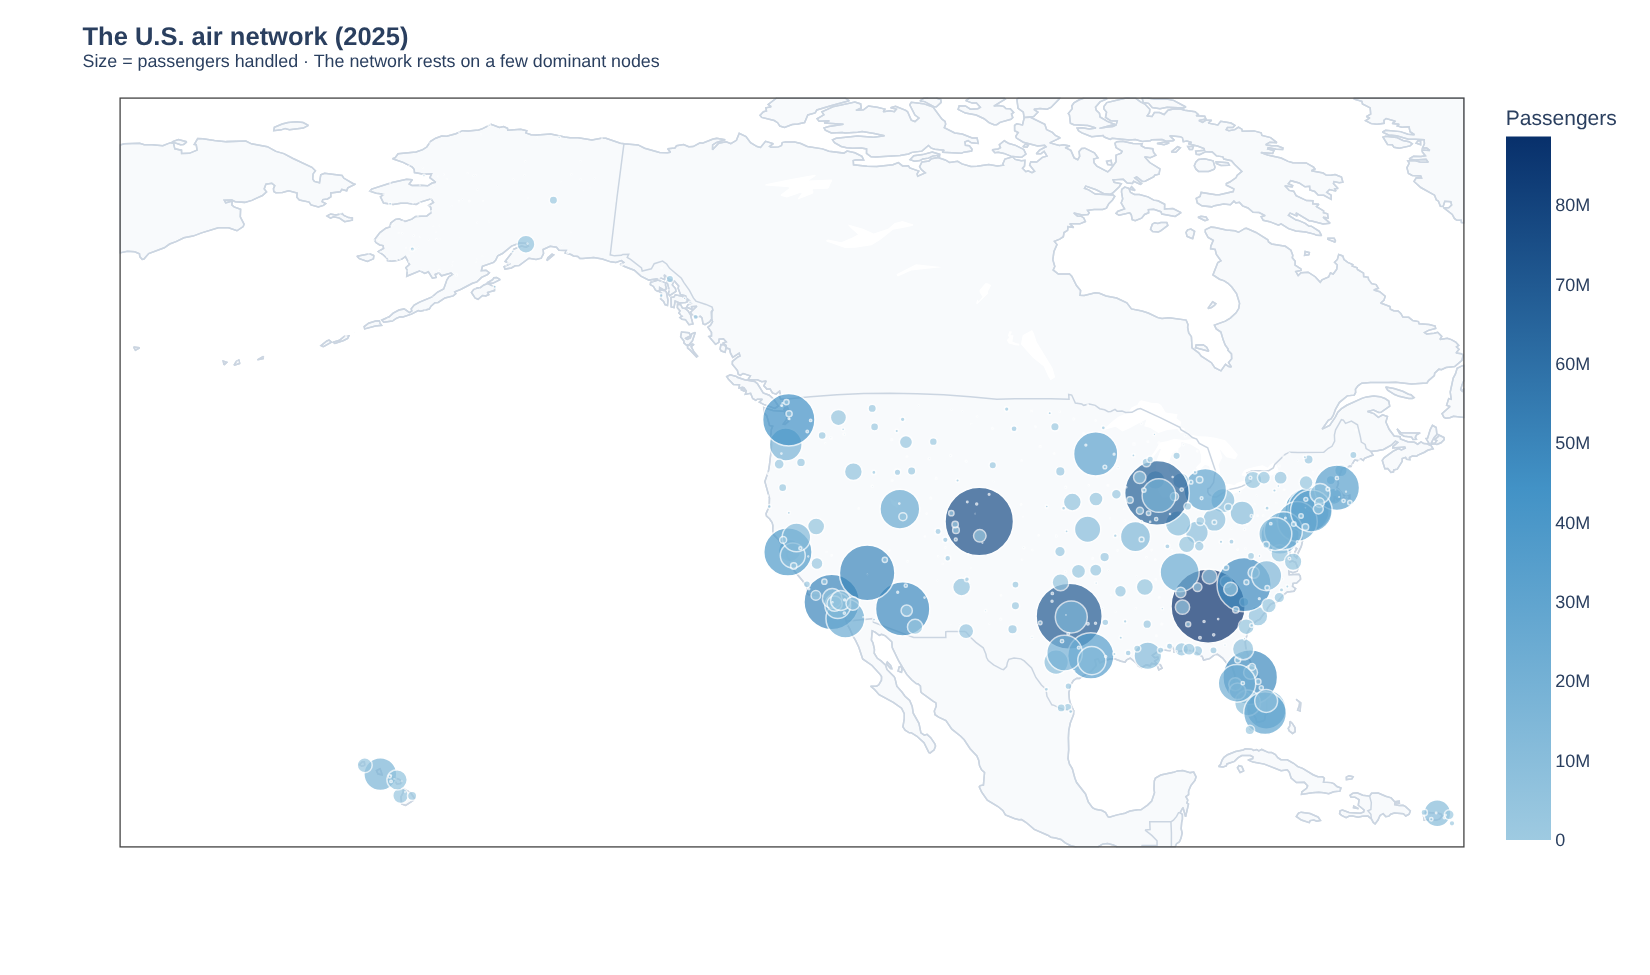

In [8]:
# Base map: where the airports are and how big they are
geo = nodes.dropna(subset=["lat", "lon"]).copy()  # drop airports without coordinates

fig = px.scatter_geo(geo,
                     lat="lat",
                     lon="lon",
                     size="passengers",
                     hover_name="name",
                     size_max=35,
                     template=TEMPLATE,
                     color="passengers",
                     color_continuous_scale=[[0, "#9ecae1"], [0.5, "#4292c6"], [1, "#08306b"]],
                     hover_data={"lat": False, "lon": False, "degree": ":,.0f", "passengers": ":,.0f"})

fig.update_geos(**GEO)
fig.update_layout(
    title="<b>The U.S. air network (2025)</b><br><sup>Size = passengers handled · The network rests on a few dominant nodes</sup>",
    coloraxis_showscale=True, coloraxis_colorbar=dict(title="Passengers"), height=650)

show(fig, "03_network_map")

## Storytelling

## "Being big is not the same as being a critical bridge"

This is the most interesting finding. It comes from crossing **degree** (how connected an airport is) against **betweenness** (how much of a *bridge* it is).

Most airports follow the general pattern: the more connections, the more bridge role... but **Anchorage (ANC)** and **Fairbanks (FAI)** break away completely: they have very high betweenness with relatively few connections.
- Why? They are the **main gateways between dozens of remote Alaskan airports and the rest of the country**. They are *hidden bridges*: not giants in passengers, but if they fail, a large part of a region is cut off.

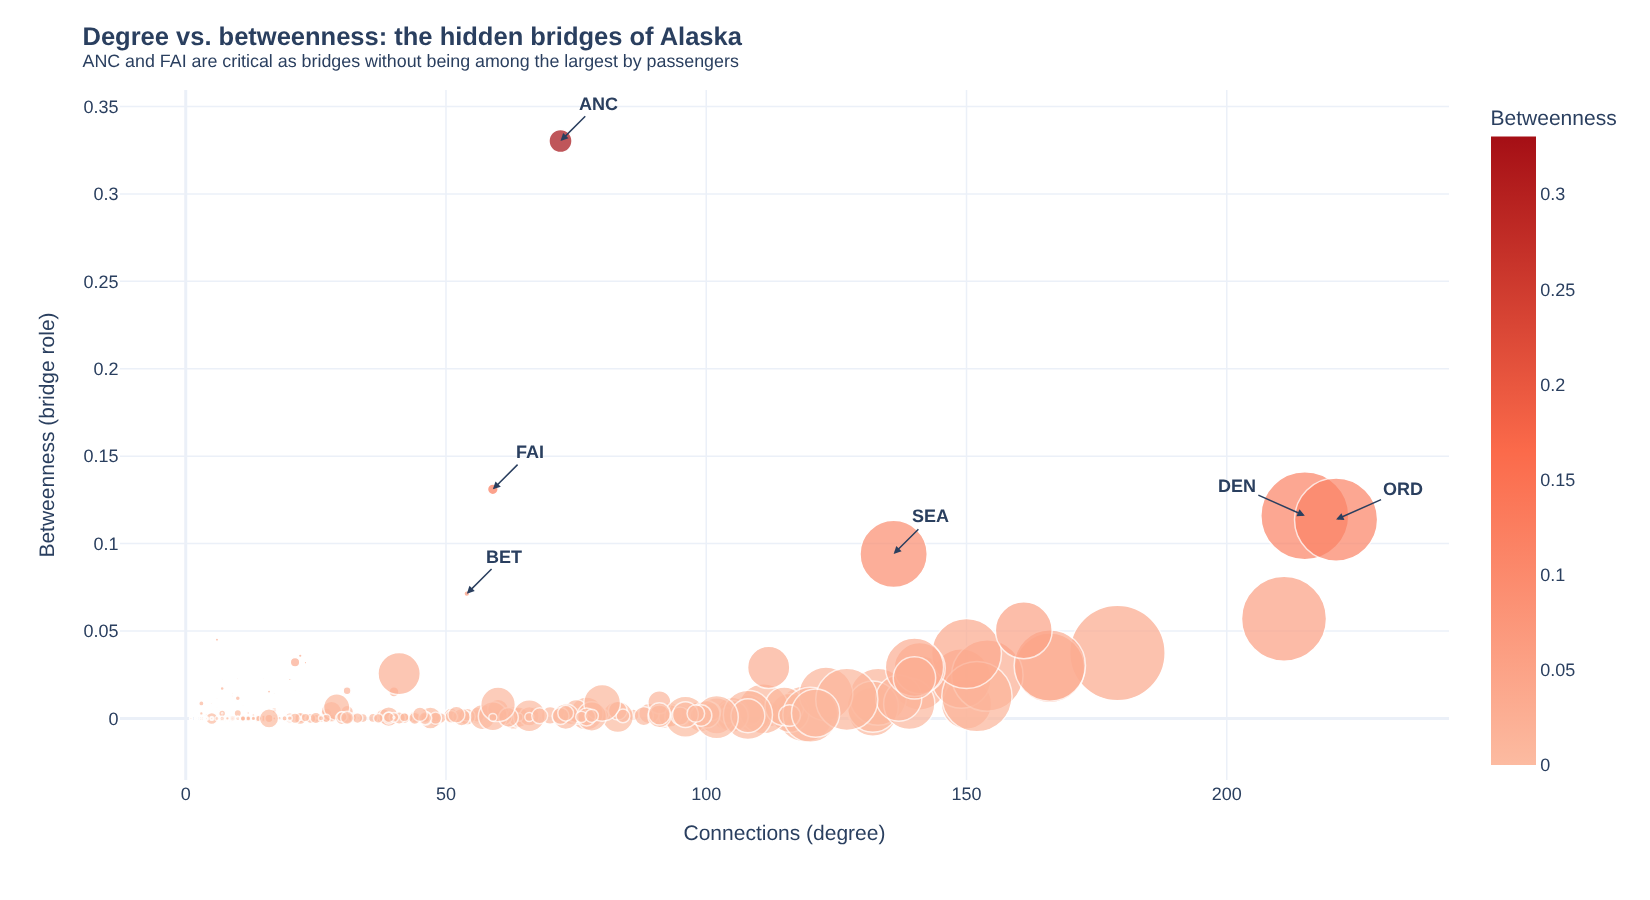

In [9]:
fig = px.scatter(nodes,
                 x="degree",
                 y="betweenness",
                 size="passengers",
                 hover_name="name",
                 template=TEMPLATE,
                 size_max=45,
                 hover_data={"degree": ":,.0f", "betweenness": ":.3f", "passengers": ":,.0f"},
                 color="betweenness",
                 color_continuous_scale=[[0, "#fcbba1"], [0.5, "#fb6a4a"], [1, "#a50f15"]])

# Annotate the most relevant bridges and hubs
highlight = nodes.sort_values("betweenness", ascending=False).head(6)  # top 6 by betweenness
offsets = {"DEN": (-45, -20), "ORD": (45, -20)}  # separate overlapping labels
for _, r in highlight.iterrows():
    ax, ay = offsets.get(r["IATA"], (25, -25))
    fig.add_annotation(x=r["degree"], y=r["betweenness"], text=f"<b>{r['IATA']}</b>",
                       showarrow=True, arrowhead=2, ax=ax, ay=ay, font=dict(size=12))

fig.update_layout(
    title="<b>Degree vs. betweenness: the hidden bridges of Alaska</b><br><sup>ANC and FAI are critical as bridges without being among the largest by passengers</sup>",
    xaxis_title="Connections (degree)", yaxis_title="Betweenness (bridge role)",
    coloraxis_showscale=True, coloraxis_colorbar=dict(title="Betweenness"), height=600)

show(fig, "04_degree_vs_betweenness")

## The graph on the map

Drawing all 8,375 routes at once would produce a cluttered visualization that loses its purpose. Instead we show the **backbone**: the ~220 busiest routes in shades of blue (the deeper the blue, the more passengers), with context airports in gray and the main hubs colored by their bridge role.
- This reveals the real structure: a dense core in the east and center, and the long spokes that hold Alaska together.

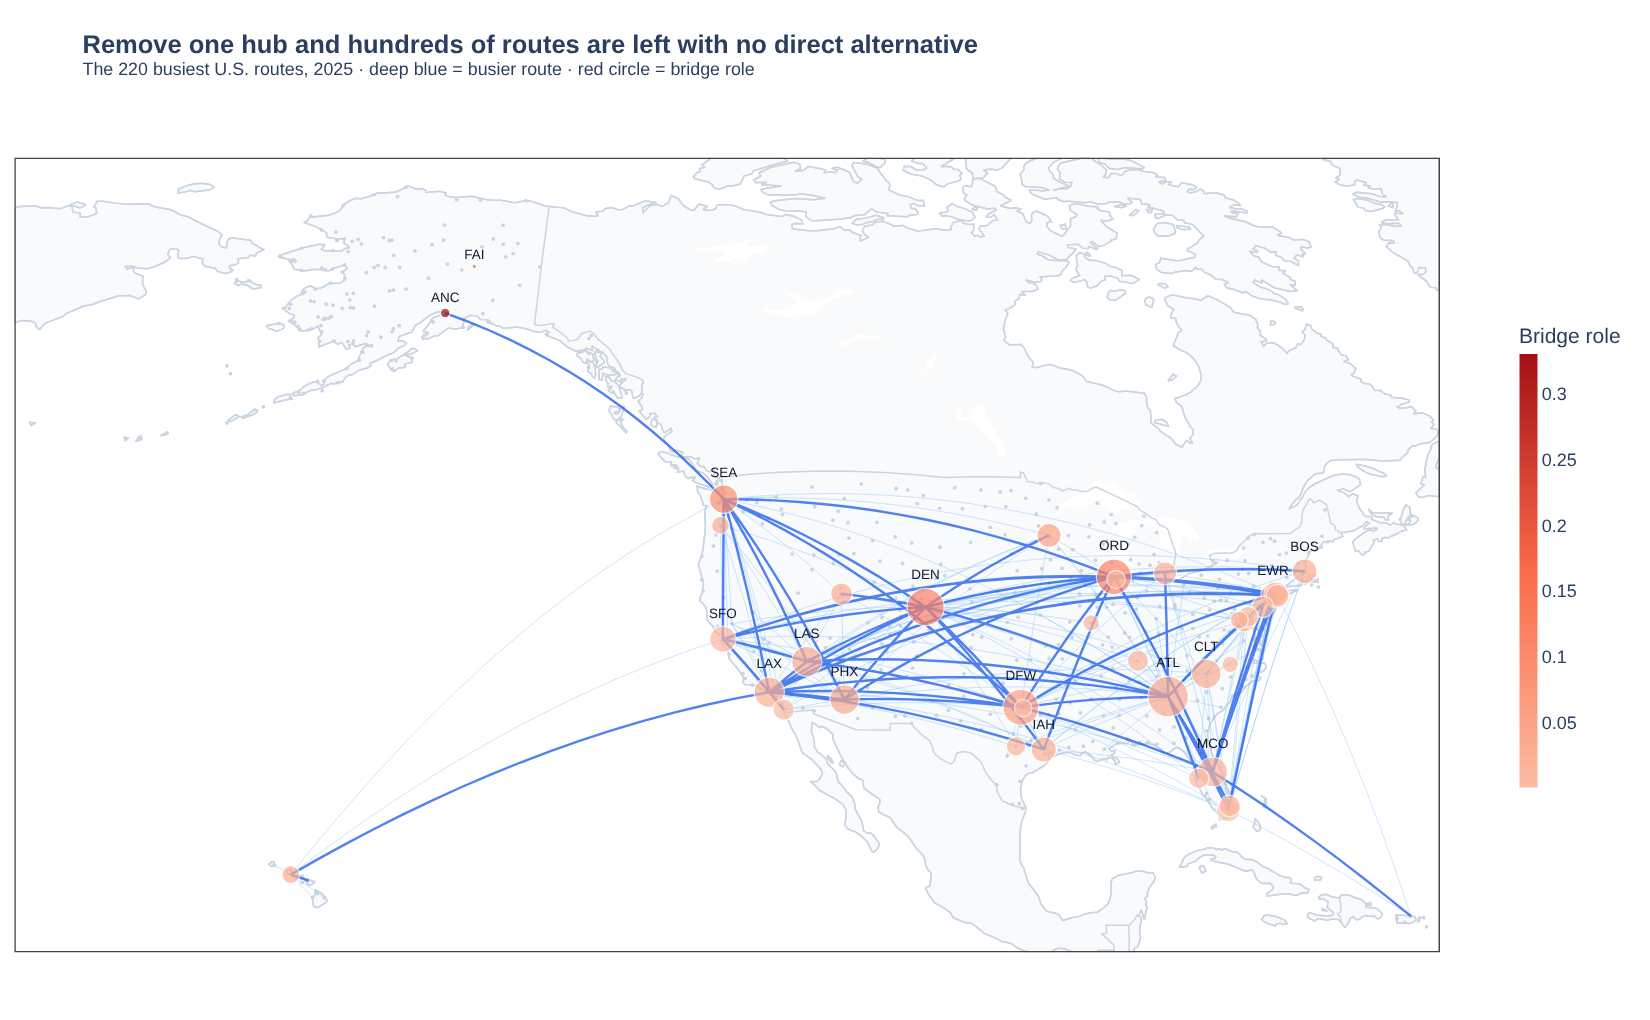

In [10]:
geo = nodes.dropna(subset=["lat", "lon"]).set_index("IATA")
available = set(geo.index)

# Sort edges by passengers and keep only the backbone (readability)
rows = [(a, b, d["passengers"]) for a, b, d in G.edges(data=True) if a in available and b in available]  # both ends need coordinates
route_df = pd.DataFrame(rows, columns=["a", "b", "pax"]).sort_values("pax", ascending=False)
tier_high = route_df.head(60)        # trunk routes
tier_mid = route_df.iloc[60:220]     # secondary routes

def _segments(sub):
    lons, lats = [], []
    for _, r in sub.iterrows():
        lons += [geo.loc[r.a, "lon"], geo.loc[r.b, "lon"], None]
        lats += [geo.loc[r.a, "lat"], geo.loc[r.b, "lat"], None]
    return lons, lats

fig = go.Figure()

# layer 0: all airports as context (light gray)
fig.add_trace(go.Scattergeo(lon=geo["lon"], lat=geo["lat"], mode="markers",
              marker=dict(size=2.5, color="#cbd5e1"), hoverinfo="skip"))

# layer 1: secondary routes (light blue, thin)
lons, lats = _segments(tier_mid)
fig.add_trace(go.Scattergeo(lon=lons, lat=lats, mode="lines",
              line=dict(width=0.6, color="#93c5fd"), opacity=0.5, hoverinfo="skip"))

# layer 2: busiest trunk routes (deep blue, thick)
lons, lats = _segments(tier_high)
fig.add_trace(go.Scattergeo(lon=lons, lat=lats, mode="lines",
              line=dict(width=1.6, color="#2563eb"), opacity=0.8, hoverinfo="skip"))

# layer 3: main hubs (size = passengers, color = betweenness)
base = geo.reset_index()
hubs = base.sort_values("passengers", ascending=False).head(35)  # top 35 airports
bridges = base[base["IATA"].isin(["ANC", "FAI"]) & ~base["IATA"].isin(hubs["IATA"])]  # the 2 key Alaskan bridges
hubs = pd.concat([hubs, bridges], ignore_index=True)  # make sure the Alaskan bridges are included

to_label = set(hubs.head(14)["IATA"]) | {"ANC", "FAI"}  # union of both sets
hubs["txt"] = hubs["IATA"].where(hubs["IATA"].isin(to_label), "")
hubs["hover"] = ("<b>" + hubs["name"].fillna(hubs["IATA"]) + "</b><br>Passengers: "
                 + hubs["passengers"].map("{:,.0f}".format) + "<br>Bridge role: "
                 + hubs["betweenness"].map("{:.3f}".format))

fig.add_trace(go.Scattergeo(lon=hubs["lon"], lat=hubs["lat"], mode="markers+text",
              marker=dict(size=np.sqrt(hubs["passengers"]) / 350, color=hubs["betweenness"],
                          colorscale=[[0, "#fcbba1"], [0.5, "#fb6a4a"], [1, "#a50f15"]], line=dict(width=0.8, color="white"), cmin=0,
                          showscale=True, colorbar=dict(title="Bridge role", thickness=12, len=0.55, x=0.92, xanchor="left")),
              text=hubs["txt"], textposition="top center",
              textfont=dict(size=9, color="#0f172a"),
              hovertext=hubs["hover"], hoverinfo="text"))

fig.update_layout(showlegend=False, template=TEMPLATE,
    title="<b>Remove one hub and hundreds of routes are left with no direct alternative</b><br><sup>The 220 busiest U.S. routes, 2025 · deep blue = busier route · red circle = bridge role</sup>",
    geo=GEO, height=680, margin=dict(t=70, b=10, l=10, r=10))

fig.update_geos(domain=dict(x=[0.0, 0.88]))

show(fig, "05_backbone_routes_map")

## What happens if the hubs fail?

We simulate three scenarios and measure the **size of the largest connected component** (what fraction of airports can still reach each other):

1. **Targeted attack:** remove airports in order of betweenness (bridges first).
2. **Degree attack:** remove airports in order of number of connections (biggest hubs first).
3. **Random failures:** remove airports at random.

Attacking the bridges wrecks the network; losing nodes at random barely matters.

,removed,targeted,degree,random
0,0,1.00,1.00,1.00
1,1,0.98,0.98,1.00
2,2,0.97,0.96,1.00
3,3,0.95,0.95,0.97
4,4,0.93,0.95,0.97


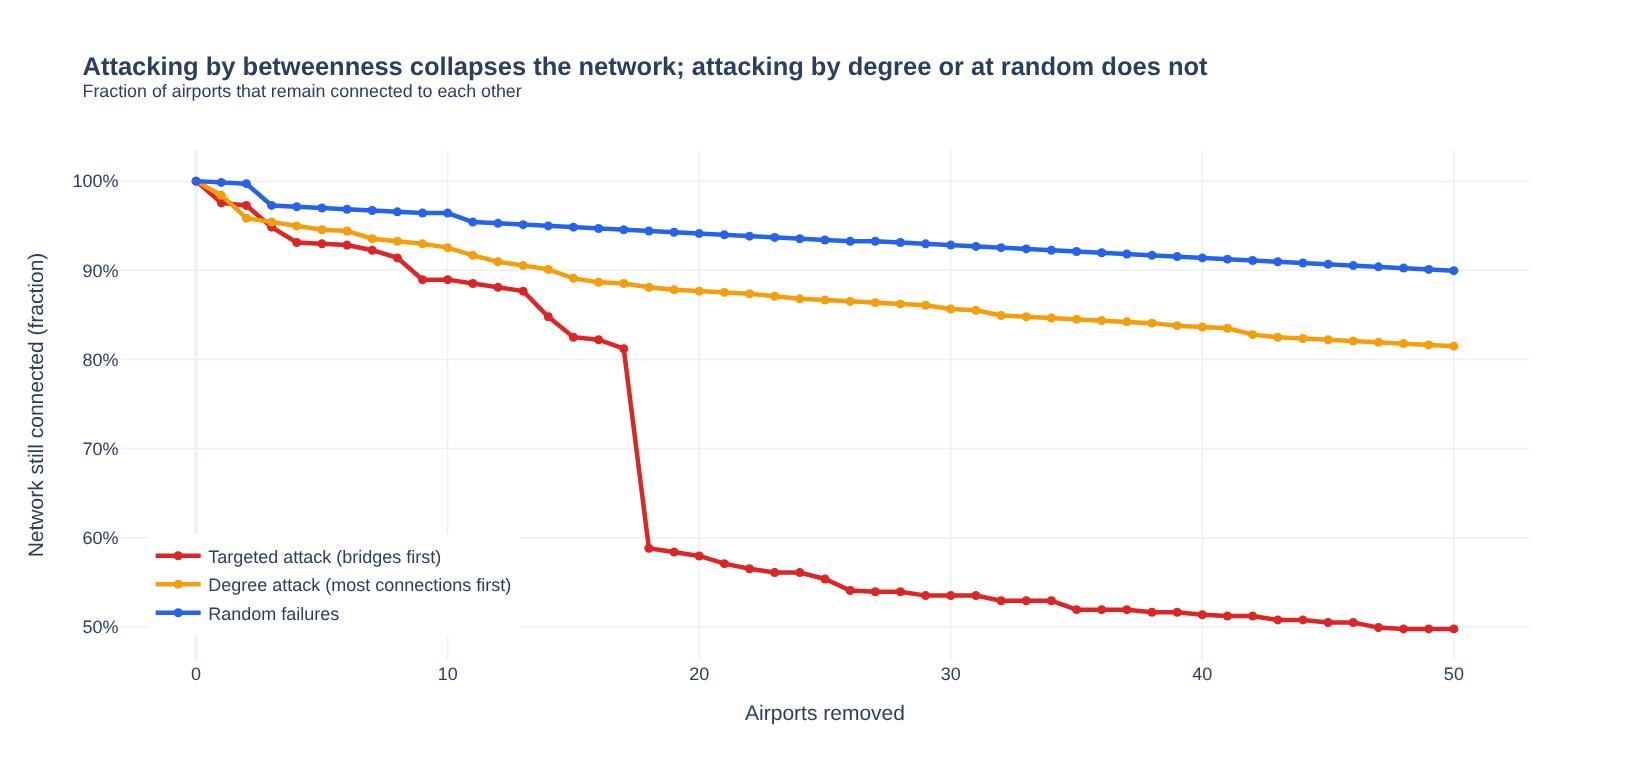

In [ ]:
N = G.number_of_nodes()

def lcc_fraction(g):
    """Fraction of the original airports that sit in the largest connected component."""
    return len(max(nx.connected_components(g), key=len)) / N if g.number_of_nodes() else 0

K = 50  # how many airports we remove
order_targeted = [n for n, _ in sorted(betweenness.items(), key=lambda x: -x[1])]
order_degree = [n for n, _ in sorted(degree.items(), key=lambda x: -x[1])]  # ranking by number of connections

rng = np.random.default_rng(7)
order_random = list(rng.permutation(list(G.nodes())))

curve = {"removed": list(range(K + 1)), "targeted": [1.0], "degree": [1.0], "random": [1.0]}

H = G.copy()
for n in order_targeted[:K]:
    H.remove_node(n); curve["targeted"].append(lcc_fraction(H))

H = G.copy()  # restart clean, same pattern as the other blocks
for n in order_degree[:K]:
    H.remove_node(n); curve["degree"].append(lcc_fraction(H))

H = G.copy()
for n in order_random[:K]:
    H.remove_node(n); curve["random"].append(lcc_fraction(H))

curve_df = pd.DataFrame(curve)
display(curve_df.head())

fig = go.Figure()
fig.add_trace(go.Scatter(x=curve_df["removed"], y=curve_df["targeted"], mode="lines+markers",
              name="Targeted attack (bridges first)", line=dict(color=RED, width=3)))

fig.add_trace(go.Scatter(x=curve_df["removed"], y=curve_df["degree"], mode="lines+markers",
              name="Degree attack (most connections first)", line=dict(color=AMBER, width=3)))

fig.add_trace(go.Scatter(x=curve_df["removed"], y=curve_df["random"], mode="lines+markers",
              name="Random failures", line=dict(color=BLUE, width=3)))

fig.update_layout(
    title="<b>Attacking by betweenness collapses the network; attacking by degree or at random does not</b><br><sup>Fraction of airports that remain connected to each other</sup>",
    xaxis_title="Airports removed", yaxis_title="Network still connected (fraction)",
    yaxis_tickformat=".0%", template=TEMPLATE, legend=dict(x=0.02, y=0.05), height=520)

show(fig, "06_failure_simulation")

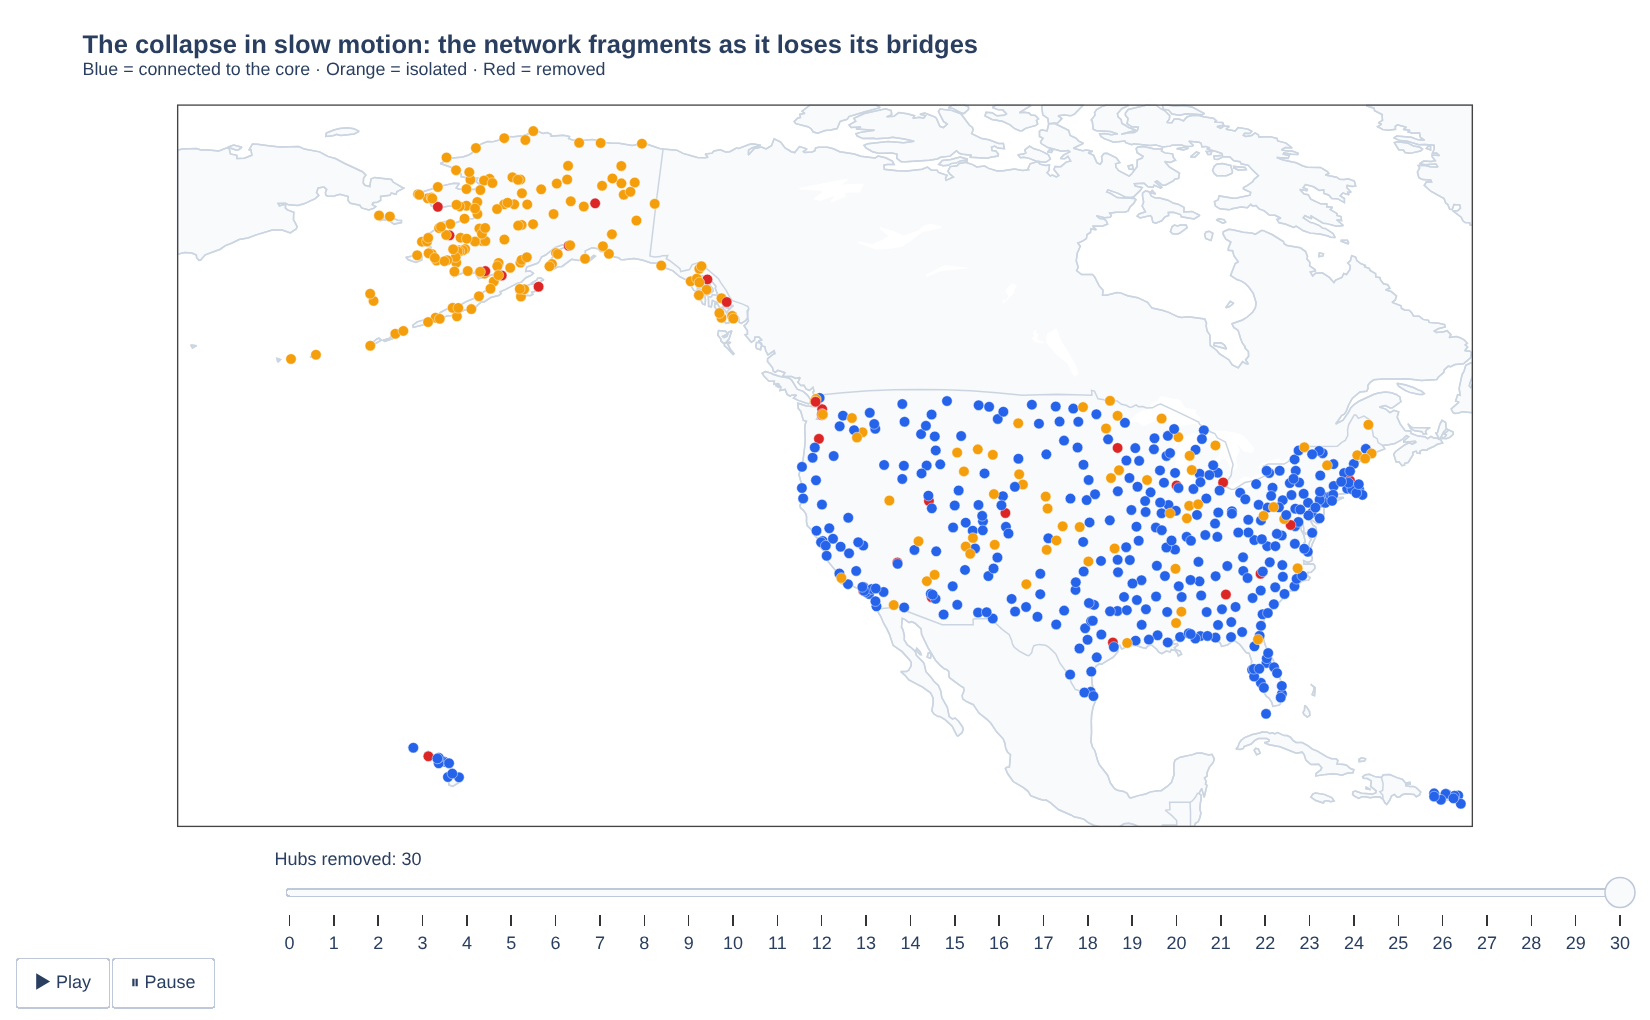

In [12]:
# Animation: how the network fragments on the map as hubs are removed one by one
geo = nodes.dropna(subset=["lat", "lon"]).set_index("IATA")
steps = 30
order = [n for n in order_targeted if n in geo.index][:steps]

frames = []
for k in range(steps + 1):
    removed = set(order[:k])
    H = G.copy(); H.remove_nodes_from(removed)
    core = max(nx.connected_components(H), key=len) if H.number_of_nodes() else set()
    colors = []
    for iata in geo.index:
        if iata in removed:
            colors.append(RED)
        elif iata in core:
            colors.append(BLUE)
        else:
            colors.append(AMBER)  # isolated
    frames.append(go.Frame(name=str(k), data=[go.Scattergeo(
        lon=geo["lon"], lat=geo["lat"], mode="markers",
        marker=dict(size=7, color=colors, line=dict(width=0.3, color="white")),
        text=geo["name"], hoverinfo="text")]))

f0 = frames[0].data[0]

fig = go.Figure(data=[f0], frames=frames)
fig.update_layout(
    title="<b>The collapse in slow motion: the network fragments as it loses its bridges</b><br><sup>Blue = connected to the core · Orange = isolated · Red = removed</sup>",
    geo=GEO, template=TEMPLATE, height=680, margin=dict(t=70, b=70, l=10, r=10),
    updatemenus=[dict(type="buttons", direction="right", showactive=False, x=0.0, xanchor="left", y=-0.18, yanchor="top", pad=dict(t=0),
        buttons=[dict(label="▶ Play", method="animate",
                      args=[None, dict(frame=dict(duration=400, redraw=True), fromcurrent=True)]),
                 dict(label="⏸ Pause", method="animate",
                      args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate")])])],
    sliders=[dict(active=0, x=0.16, len=0.84, pad=dict(t=10), currentvalue=dict(prefix="Hubs removed: "),
                  steps=[dict(method="animate", label=str(k),
                             args=[[str(k)], dict(mode="immediate",
                                   frame=dict(duration=0, redraw=True))]) for k in range(steps + 1)])])

show(fig, "07_collapse_animation")

## Conclusions

**Data-driven recommendation: priority airports for resilience.**

The table below ranks airports by a combined criticality index (normalized betweenness + degree, weighted 60/40). These are the nodes where operational redundancy should be concentrated.

In [13]:
ranking = nodes.copy()

ranking["criticality"] = (
    0.6 * ranking["betweenness"] / ranking["betweenness"].max() +
    0.4 * ranking["degree"] / ranking["degree"].max())

ranking = ranking.sort_values("criticality", ascending=False).head(10)
ranking[["IATA", "name", "degree", "passengers", "betweenness", "criticality"]].reset_index(drop=True)

,IATA,name,degree,passengers,betweenness,criticality
0,ANC,Ted Stevens Anchorage International Airport,72,"5,186,461.00",0.33,0.73
1,ORD,Chicago O'Hare International Airport,221,"67,236,356.00",0.11,0.61
2,DEN,Denver International Airport,215,"75,407,354.00",0.12,0.60
3,DFW,Dallas Fort Worth International Airport,211,"70,345,915.00",0.06,0.49
4,SEA,Seattle Tacoma International Airport,136,"44,082,778.00",0.09,0.42
5,ATL,Hartsfield Jackson Atlanta International Airport,179,"88,602,612.00",0.04,0.39
6,MSP,Minneapolis-St Paul International/Wold-Chamber...,161,"31,453,734.00",0.05,0.38
7,LAS,McCarran International Airport,166,"49,558,971.00",0.03,0.36
8,CLT,Charlotte Douglas International Airport,166,"47,261,793.00",0.03,0.35
9,FAI,Fairbanks International Airport,59,"1,116,053.00",0.13,0.34


### What I learned

**From the project:**
- **Big ≠ critical.** The Alaskan bridges (ANC, FAI) show that the right metric matters: betweenness revealed critical nodes that a simple passenger ranking would have hidden.
- **Cleaning is deciding.** Filtering to class F (scheduled service) and to the main connected component was not cosmetic: it defined which network was being analyzed.

**From the course:**
- A good title communicates a finding, not the name of an axis.
- Every chart should **advance the narrative**, not just decorate.
- Graphs, maps, interaction and animation make sense when they serve a concrete decision question.

---

### References
- Bureau of Transportation Statistics (BTS). *T-100 Domestic Segment (U.S. Carriers)*, 2025. U.S. DOT. Public domain. https://www.transtats.bts.gov/
- OpenFlights. *Airport database* (`jpatokal/openflights`). Open Database License. https://openflights.org/data.html
- Libraries: pandas, NumPy, NetworkX, Plotly.
- AI assistance: Claude (Anthropic) for visualization design; results verified against the real data.